In [2]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()



In [3]:
df_us_software_pivot = pd.read_csv(
    "https://lukeb.co/software_csv",
    index_col="job_posted_month"
)

In [4]:
df_us = df[df['job_location'] == 'United States']

In [5]:
df_us['job_posted_date'] = pd.to_datetime(df_us['job_posted_date'])

df_us['job_posted_month'] = df_us['job_posted_date'].dt.strftime('%B')

In [6]:
df_us_pivot = df_us.pivot_table(index='job_posted_month', columns='job_title_short', aggfunc='size')

In [7]:
df_us_pivot = df_us.pivot_table(
    index="job_posted_month",
    columns="job_title_short",
    values="salary_year_avg",
    aggfunc="median"
)

In [8]:
df_us_pivot = df_us_pivot.reset_index()

In [9]:
print(df_us_software_pivot.index)

Index(['January', 'February', 'March', 'April', 'May', 'June', 'July',
       'August', 'September', 'October', 'November', 'December'],
      dtype='str', name='job_posted_month')


In [10]:
df_us_software_pivot = df_us_software_pivot.reset_index()

In [11]:
print(df_us_pivot.columns.tolist())
print(df_us_software_pivot.columns.tolist())

['job_posted_month', 'Business Analyst', 'Cloud Engineer', 'Data Analyst', 'Data Engineer', 'Data Scientist', 'Machine Learning Engineer', 'Senior Data Analyst', 'Senior Data Engineer', 'Senior Data Scientist', 'Software Engineer']
['job_posted_month', 'Front-End Developer', 'Back-End Developer', 'Full-Stack Developer', 'UI/UX Designer']


In [12]:
df_merge = df_us_pivot.merge(
    df_us_software_pivot,
    on="job_posted_month"
)

In [13]:
import pandas as pd

df_companies = pd.DataFrame({
    'company_name': [
        'Booz Allen Hamilton',
        'Capital One',
        'Dice',
        'Harnham',
        'Meta'
    ],
    'company_size': [
        'Large',
        'Large',
        'Medium',
        'Small',
        'Very Large'
    ]
})

df_companies

,company_name,company_size
0,Booz Allen Hamilton,Large
1,Capital One,Large
2,Dice,Medium
3,Harnham,Small
4,Meta,Very Large


In [14]:
df_merged = df.merge(
    df_companies,
    on='company_name')

In [15]:
df_merged 

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,company_size
0,Senior Data Engineer,Senior Data Engineer (Work from home Eligible),"Wilmington, DE",via WDHN Jobs,Full-time,False,"Texas, United States",2023-03-29 13:32:03,False,True,United States,NaN,NaN,NaN,Capital One,"['scala', 'python', 'nosql', 'mongo', 'shell',...","{'cloud': ['redshift', 'snowflake', 'aws', 'az...",Large
1,Senior Data Engineer,Senior/Lead Data Engineer,"Dover, DE",via SaluteMyJob,Full-time and Part-time,False,"Illinois, United States",2023-12-04 13:08:34,False,True,United States,NaN,NaN,NaN,Capital One,"['java', 'scala', 'python', 'nosql', 'sql', 'm...","{'cloud': ['redshift', 'snowflake', 'aws', 'az...",Large
2,Data Scientist,Health Data Scientist,"Bethesda, MD",via Trabajo.org,Full-time,False,Georgia,2023-11-12 13:49:48,False,False,United States,NaN,NaN,NaN,Booz Allen Hamilton,NaN,NaN,Large
3,Senior Data Scientist,"Mission Data Scientist, Senior - Security Clea...","Fayetteville, NC",via My Panhandle Jobs,Full-time,False,Georgia,2023-04-09 14:21:49,False,True,United States,NaN,NaN,NaN,Booz Allen Hamilton,"['python', 'r', 'postgresql', 'pandas', 'table...","{'analyst_tools': ['tableau', 'splunk'], 'data...",Large
4,Data Scientist,"Data Scientist, Mid Jobs","Washington, DC",via Clearance Jobs,Full-time,False,Georgia,2023-03-21 14:02:40,False,True,United States,NaN,NaN,NaN,Booz Allen Hamilton,"['python', 'java', 'r', 'c++', 'aws', 'azure',...","{'cloud': ['aws', 'azure'], 'libraries': ['spa...",Large
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10843,Senior Data Engineer,"Health and Civil Data Engineer, Senior - Now H...","Bethesda, MD",via Snagajob,Full-time and Part-time,False,Georgia,2023-10-08 06:50:59,False,True,United States,hour,NaN,61.159996,Booz Allen Hamilton,"['python', 'sql', 'scala', 'java', 'shell', 'n...","{'cloud': ['aws', 'azure', 'databricks', 'reds...",Large
10844,Data Analyst,"Director, Data Governance","Wichita Falls, TX",via Trabajo.org,Full-time,False,Sudan,2023-01-29 07:20:10,False,False,Sudan,NaN,NaN,NaN,Capital One,NaN,NaN,Large
10845,Data Scientist,"Data Scientist, Lead","Washington, DC",via Snagajob,Full-time and Part-time,False,Georgia,2023-11-01 06:58:10,False,True,United States,hour,NaN,47.620003,Booz Allen Hamilton,"['databricks', 'azure', 'aws']","{'cloud': ['databricks', 'azure', 'aws']}",Large
10846,Data Scientist,Data Scientist,"Arlington, VA",via Snagajob,Full-time and Part-time,False,Georgia,2023-11-01 06:58:02,False,True,United States,hour,NaN,47.620003,Booz Allen Hamilton,"['python', 'r', 'pyspark']","{'libraries': ['pyspark'], 'programming': ['py...",Large


In [16]:
pd.read_csv("https://lukeb.co/software_csv")

,job_posted_month,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
0,January,13619,9827,5108,4348
1,February,11456,9116,7298,4284
2,March,11102,8178,5814,4159
3,April,14037,9209,7232,4220
4,May,12126,8864,6718,4980
5,June,12003,8065,5902,4781
6,July,11914,8061,6839,4344
7,August,11571,8191,7413,4104
8,September,14016,8447,6139,4094
9,October,11419,8476,5026,4389


In [17]:
df_us_software_pivot = pd.read_csv("https://lukeb.co/software_csv", index_col='job_posted_month')
df_us_software_pivot

,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,
January,13619,9827,5108,4348
February,11456,9116,7298,4284
March,11102,8178,5814,4159
April,14037,9209,7232,4220
May,12126,8864,6718,4980
June,12003,8065,5902,4781
July,11914,8061,6839,4344
August,11571,8191,7413,4104
September,14016,8447,6139,4094


In [18]:
df_us_pivot.merge(df_us_software_pivot, on='job_posted_month')

,job_posted_month,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
0,April,NaN,NaN,105000.00,136735.00,126095.5,157500.0,178000.0,141250.0,157500.00,NaN,14037,9209,7232,4220
1,August,NaN,NaN,NaN,97444.00,120000.0,NaN,NaN,140000.0,162500.00,NaN,11571,8191,7413,4104
2,December,NaN,NaN,75033.75,141800.00,119500.0,123900.0,120070.0,155000.0,125000.00,125000.0,14033,9232,6731,4367
3,February,NaN,NaN,114062.50,145000.00,132500.0,152500.0,98500.0,135000.0,157500.00,NaN,11456,9116,7298,4284
4,January,NaN,NaN,76250.00,135600.00,152500.0,169250.0,111175.0,145000.0,157500.00,197500.0,13619,9827,5108,4348
5,July,NaN,NaN,100500.00,92500.00,145000.0,NaN,NaN,147500.0,166250.00,184500.0,11914,8061,6839,4344
6,June,NaN,NaN,92750.00,88750.00,170000.0,110000.0,NaN,140000.0,170000.00,NaN,12003,8065,5902,4781
7,March,NaN,58000.5,NaN,132500.00,128433.5,142500.0,NaN,146250.0,140000.00,217500.0,11102,8178,5814,4159
8,May,NaN,NaN,205000.00,120000.00,136950.0,190000.0,NaN,325000.0,170000.00,NaN,12126,8864,6718,4980
9,November,100000.0,NaN,94559.00,121954.75,130000.0,185500.0,119450.0,125000.0,170500.00,NaN,13771,9034,5653,4099


In [20]:
print(df_us_pivot.sum())

job_title_short
job_posted_month             AprilAugustDecemberFebruaryJanuaryJulyJuneMarc...
Business Analyst                                                      100000.0
Cloud Engineer                                                         58000.5
Data Analyst                                                         961905.25
Data Engineer                                                       1469783.75
Data Scientist                                                       1650979.0
Machine Learning Engineer                                            1231150.0
Senior Data Analyst                                                   794695.0
Senior Data Engineer                                                 1901250.0
Senior Data Scientist                                               1914442.75
Software Engineer                                                     724500.0
dtype: object


In [28]:
top_5 = (
    df_us_pivot
    .sum(numeric_only=True)
    .sort_values(ascending=False)
    .head(5)
    .index
    .to_list()
)
top_5

TypeError: IndexOpsMixin.tolist() takes 1 positional argument but 2 were given

In [56]:
df_us_merged = df_us_pivot.merge(
    df_us_software_pivot,
    left_index=True,
    right_index=True
)

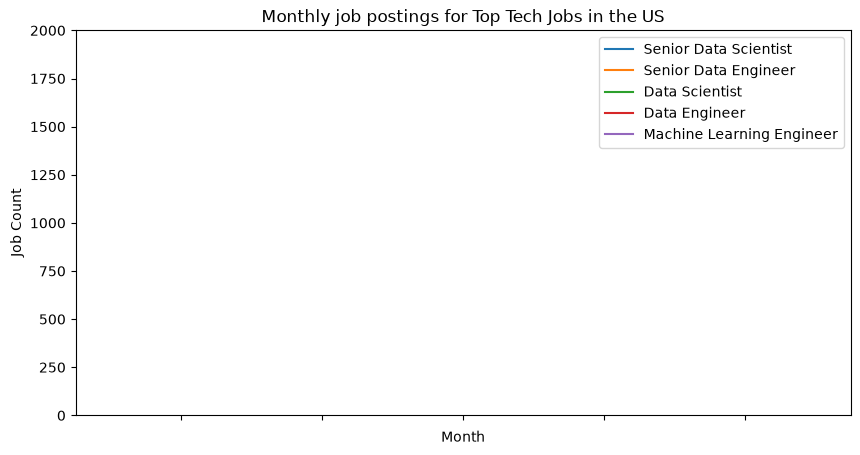

In [57]:
df_us_merged[top_5].plot(figsize=(10, 5))

plt.title('Monthly job postings for Top Tech Jobs in the US')
plt.xlabel('Month')
plt.ylabel('Job Count')
plt.ylim(0, 2000)
plt.show()

In [46]:
top_5

['Senior Data Scientist',
 'Senior Data Engineer',
 'Data Scientist',
 'Data Engineer',
 'Machine Learning Engineer']

In [55]:
df_us_merged[top_5].isna().sum()

Senior Data Scientist        0
Senior Data Engineer         0
Data Scientist               0
Data Engineer                0
Machine Learning Engineer    4
dtype: int64

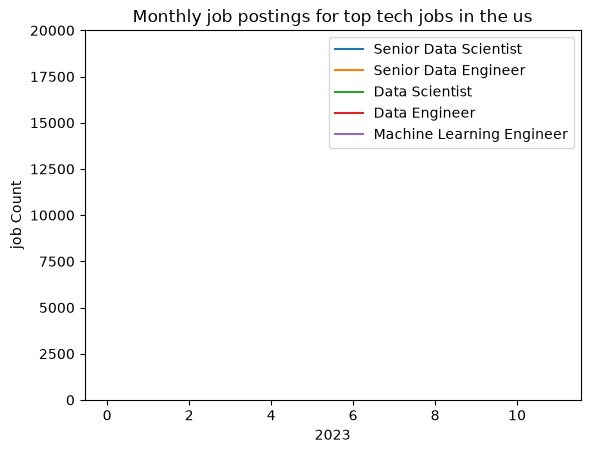

In [47]:
df_us_merged[top_5].plot(kind='line')
plt.title('Monthly job postings for top tech jobs in the us')
plt.xlabel('2023')
plt.ylabel('job Count')
plt.ylim(0, 20000)
plt.legend()
plt.show()
